# 01 · Training fake-account classifiers on the Kaggle data

**Goal.** Train three classifiers (logistic regression, random forest, XGBoost) to tell fake/spam Instagram accounts from genuine ones using 11 public profile features, and test how the **class ratio** in training and test data changes the results.

**Two setups**
- **Balanced (50/50):** Kaggle `train.csv` / `test.csv` as given, half fake and half genuine.
- **Imbalanced (90/10):** every genuine account is kept and fakes are downsampled to 10%, in both train and test. That leaves only about 32 fake training accounts, so this is repeated over 10 random seeds. The seed-0 models are saved.

Every model is cross-evaluated on both kinds of test set. The six saved models are used again in notebook 03 on live Instagram data.

This notebook is self-contained: all code is defined here.

In [1]:
from pathlib import Path
import os
# Run from the project root (the folder that holds data/ and models/), wherever Jupyter was started.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
os.chdir(ROOT)

In [2]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEEDS = 10          # random 90/10 samples
FAKE_SHARE = 0.10   # fake share in the imbalanced setup
MODELS_DIR = Path("models")
RESULTS_DIR = Path("results")

In [3]:
# The 11 features, named as in the Kaggle "Instagram Fake Spammer Genuine Accounts" files.
FEATURES = [
    "profile pic",           # 1 if the account has a (non-default) profile picture
    "nums/length username",  # share of digits in the username
    "fullname words",        # number of words in the full name
    "nums/length fullname",  # share of digits in the full name
    "name==username",        # 1 if full name equals username
    "description length",    # characters in the bio
    "external URL",          # 1 if the profile has an external link
    "private",               # 1 if the account is private
    "#posts",
    "#followers",
    "#follows",
]
LABEL = "fake"  # 1 = fake, 0 = genuine
COUNT_FEATURES = ["description length", "#posts", "#followers", "#follows"]

## 1. Data

In [4]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(f"train: {len(train)} rows, {train[LABEL].mean():.0%} fake | test: {len(test)} rows, {test[LABEL].mean():.0%} fake")
print(f"exact duplicate rows: train {train.duplicated().sum()}, test {test.duplicated().sum()}")

# Duplicates are dropped from train only, so the official test set stays intact.
train = train.drop_duplicates().reset_index(drop=True)
print(f"train after dropping duplicates: {len(train)} rows")

train: 576 rows, 50% fake | test: 120 rows, 50% fake
exact duplicate rows: train 2, test 2
train after dropping duplicates: 574 rows


### Quick look: how do fake and genuine accounts differ?
Medians for the count features, shares for the binary ones.

In [5]:
def class_summary(df):
    g = df.groupby(LABEL)
    out = pd.DataFrame({
        "n": g.size(),
        "median #posts": g["#posts"].median(),
        "median #followers": g["#followers"].median(),
        "median #follows": g["#follows"].median(),
        "median description length": g["description length"].median(),
        "% private": 100 * g["private"].mean(),
        "% no profile pic": 100 * (1 - g["profile pic"].mean()),
        "% external URL": 100 * g["external URL"].mean(),
        "mean digit share username": g["nums/length username"].mean(),
    }).T
    out.columns = ["genuine", "fake"]
    return out.round(2)

class_summary(train)

,genuine,fake
n,287.00,287.00
median #posts,74.00,0.00
median #followers,655.00,40.00
median #follows,430.00,71.00
median description length,27.00,0.00
% private,39.72,36.93
% no profile pic,0.70,59.23
% external URL,23.34,0.00
mean digit share username,0.04,0.29


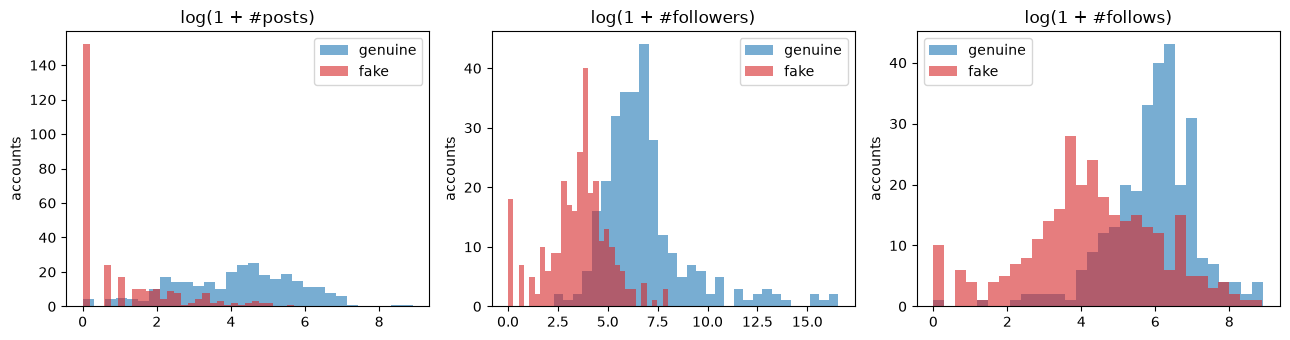

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["#posts", "#followers", "#follows"]):
    for lab, name, c in [(0, "genuine", "#1f77b4"), (1, "fake", "#d62728")]:
        ax.hist(np.log1p(train.loc[train[LABEL] == lab, col]), bins=30, alpha=0.6, color=c, label=name)
    ax.set(title=f"log(1 + {col})", ylabel="accounts")
    ax.legend()
fig.tight_layout()

Fakes typically have no posts, few followers, no bio, no external link and more digits in the username. The count features are heavily skewed (followers run from 0 to millions), so the models use `log1p` of them.

## 2. Models
Each model is a full scikit-learn `Pipeline`, so a saved model scores raw features directly.
- **LogReg:** `log1p` on counts, then standardise everything. Grid over `C`.
- **RF / XGBoost:** `log1p` on counts only (trees don't need scaling).
- In the imbalanced setup the fake class is reweighted (`class_weight="balanced"`, or `scale_pos_weight` = genuine/fake for XGBoost).

In [7]:
OTHER = [f for f in FEATURES if f not in COUNT_FEATURES]


def log_scale():
    return ColumnTransformer([
        ("counts", Pipeline([("log", FunctionTransformer(np.log1p)),
                             ("scale", StandardScaler())]), COUNT_FEATURES),
        ("other", StandardScaler(), OTHER),
    ])


def log_only():
    return ColumnTransformer([
        ("counts", FunctionTransformer(np.log1p), COUNT_FEATURES),
        ("other", "passthrough", OTHER),
    ])


def build(name, imbalanced, pos_weight=1.0, seed=0):
    """Return (pipeline, hyperparameter grid)."""
    cw = "balanced" if imbalanced else None
    if name == "logreg":
        pipe = Pipeline([("prep", log_scale()),
                         ("clf", LogisticRegression(max_iter=2000, class_weight=cw))])
        grid = {"clf__C": [0.01, 0.1, 1, 10]}
    elif name == "rf":
        pipe = Pipeline([("prep", log_only()),
                         ("clf", RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                        random_state=seed, n_jobs=-1))])
        grid = {"clf__max_depth": [None, 6, 10], "clf__min_samples_leaf": [1, 3, 5]}
    elif name == "xgb":
        pipe = Pipeline([("prep", log_only()),
                         ("clf", XGBClassifier(n_estimators=300, eval_metric="logloss",
                                               scale_pos_weight=pos_weight if imbalanced else 1.0,
                                               random_state=seed, n_jobs=-1))])
        grid = {"clf__max_depth": [2, 3, 5], "clf__learning_rate": [0.05, 0.1],
                "clf__subsample": [0.8, 1.0]}
    else:
        raise ValueError(name)
    return pipe, grid


MODEL_NAMES = ["logreg", "rf", "xgb"]

## 3. Training procedure
- **Hyperparameters:** 5-fold stratified CV grid search, scored by **PR-AUC** (average precision), which focuses on the fake class.
- **Tuned threshold:** out-of-fold probabilities from the best model pick the threshold that maximises F1. The test set is never used for this. Every model is reported at both the default 0.5 and its tuned threshold.
- **Metrics** are for the fake class (positive = 1).

In [8]:
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)


def evaluate(y_true, prob, threshold=0.5) -> dict:
    """Metrics for the fake class (positive = 1)."""
    y_true = np.asarray(y_true)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        "threshold": threshold,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob) if both else np.nan,
        "pr_auc": average_precision_score(y_true, prob) if both else np.nan,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "fpr": fp / (fp + tn) if fp + tn else np.nan,
    }

In [9]:
def best_f1_threshold(y_true, prob):
    """Threshold maximising F1 on out-of-fold predictions."""
    grid = np.linspace(0.05, 0.95, 91)
    return float(max(grid, key=lambda t: f1_score(y_true, prob >= t, zero_division=0)))


def make_imbalanced(df, fake_share, seed):
    """Keep every genuine account and sample fakes so they make up `fake_share`."""
    genuine = df[df[LABEL] == 0]
    n_fake = max(1, round(len(genuine) * fake_share / (1 - fake_share)))
    fake = df[df[LABEL] == 1].sample(n=n_fake, random_state=seed)
    return pd.concat([genuine, fake]).sample(frac=1, random_state=seed).reset_index(drop=True)


def fit(name, df, imbalanced, seed):
    X, y = df[FEATURES], df[LABEL]
    pos_weight = (y == 0).sum() / max(1, (y == 1).sum())
    pipe, grid = build(name, imbalanced, pos_weight, seed)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    search = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1)
    search.fit(X, y)
    oof = cross_val_predict(search.best_estimator_, X, y, cv=cv, method="predict_proba")[:, 1]
    return search.best_estimator_, search.best_params_, best_f1_threshold(y, oof)


def save(model, name, config, params, threshold, df):
    MODELS_DIR.mkdir(exist_ok=True)
    stem = f"{config}_{name}"
    joblib.dump(model, MODELS_DIR / f"{stem}.joblib")
    if name == "xgb":  # native XGBoost weights as well
        model.named_steps["clf"].save_model(MODELS_DIR / f"{stem}.json")
    meta = {"model": name, "config": config, "features": FEATURES,
            "n_train": len(df), "fake_share_train": float(df[LABEL].mean()),
            "best_params": params, "tuned_threshold": threshold}
    (MODELS_DIR / f"{stem}.meta.json").write_text(json.dumps(meta, indent=2, default=str))

## 4. Train and cross-evaluate
This takes a few minutes: 3 balanced fits, plus 3 × 10 imbalanced fits, each with a grid search.

In [10]:
%%time
rows, saved = [], []
imb_tests = {s: make_imbalanced(test, FAKE_SHARE, s) for s in range(SEEDS)}


def score(model, name, config, seed, thr, test_name, tdf):
    prob = model.predict_proba(tdf[FEATURES])[:, 1]
    for kind, t in [("default_0.5", 0.5), ("tuned", thr)]:
        rows.append({"model": name, "trained_on": config, "seed": seed, "test_set": test_name,
                     "threshold_type": kind, **evaluate(tdf[LABEL], prob, t)})


# Balanced models: one fit, evaluated on the balanced test set and every 90/10 test sample.
for name in MODEL_NAMES:
    model, params, thr = fit(name, train, False, 0)
    save(model, name, "balanced", params, thr, train)
    saved.append({"model": name, "trained_on": "balanced", "train rows": len(train),
                  "train fakes": int(train[LABEL].sum()), "best params": params, "tuned threshold": thr})
    score(model, name, "balanced", 0, thr, "balanced_test", test)
    for s, t in imb_tests.items():
        score(model, name, "balanced", s, thr, "imbalanced_test", t)

# Imbalanced models: one fit per seed; seed 0 is saved.
for s in range(SEEDS):
    imb_train = make_imbalanced(train, FAKE_SHARE, s)
    for name in MODEL_NAMES:
        model, params, thr = fit(name, imb_train, True, s)
        if s == 0:
            save(model, name, "imbalanced", params, thr, imb_train)
            saved.append({"model": name, "trained_on": "imbalanced", "train rows": len(imb_train),
                          "train fakes": int(imb_train[LABEL].sum()), "best params": params,
                          "tuned threshold": thr})
        score(model, name, "imbalanced", s, thr, "imbalanced_test", imb_tests[s])
        score(model, name, "imbalanced", s, thr, "balanced_test", test)

pd.DataFrame(saved)

CPU times: user 39.7 s, sys: 23.2 s, total: 1min 2s
Wall time: 1min 55s


,model,trained_on,train rows,train fakes,best params,tuned threshold
0,logreg,balanced,574,287,{'clf__C': 10},0.43
1,rf,balanced,574,287,"{'clf__max_depth': 6, 'clf__min_samples_leaf': 1}",0.41
2,xgb,balanced,574,287,"{'clf__learning_rate': 0.05, 'clf__max_depth':...",0.62
3,logreg,imbalanced,319,32,{'clf__C': 0.1},0.68
4,rf,imbalanced,319,32,"{'clf__max_depth': None, 'clf__min_samples_lea...",0.54
5,xgb,imbalanced,319,32,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.85


The table above lists the six saved models (`models/<config>_<model>.joblib`, plus `.meta.json` and the native XGBoost `.json`).

## 5. Results
Mean ± std over seeds. The balanced models have one fit, so on the balanced test set there is no std. On 90/10 test sets the std comes only from which fakes were sampled.

In [11]:
long = pd.DataFrame(rows)
keys = ["model", "trained_on", "test_set", "threshold_type"]
cols = ["precision", "recall", "f1", "roc_auc", "pr_auc", "fpr"]
summary = long.groupby(keys)[cols].agg(["mean", "std"]).round(3)
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary = summary.reset_index()

RESULTS_DIR.mkdir(exist_ok=True)
long.to_csv(RESULTS_DIR / "metrics_all_seeds.csv", index=False)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)

In [12]:
# Report-style table: tuned thresholds, both test sets.
NAMES = {"logreg": "LogReg", "rf": "RF", "xgb": "XGBoost"}
CFG = {"balanced": "50/50", "imbalanced": "90/10"}

def report_table(threshold_type="tuned"):
    s = summary[summary.threshold_type == threshold_type].set_index(["model", "trained_on", "test_set"])
    out = []
    for cfg in ["balanced", "imbalanced"]:
        for m in MODEL_NAMES:
            b, i = s.loc[(m, cfg, "balanced_test")], s.loc[(m, cfg, "imbalanced_test")]
            out.append({
                "Model": NAMES[m], "Trained on": CFG[cfg],
                "Test 50/50 P / R / F1": f"{b.precision_mean:.2f} / {b.recall_mean:.2f} / {b.f1_mean:.2f}",
                "Test 90/10 P / R / F1": f"{i.precision_mean:.2f} / {i.recall_mean:.2f} / {i.f1_mean:.2f} ± {i.f1_std:.2f}",
                "PR-AUC 50/50 → 90/10": f"{b.pr_auc_mean:.2f} → {i.pr_auc_mean:.2f}",
            })
    return pd.DataFrame(out)

print("Tuned thresholds")
display(report_table("tuned"))
print("Default threshold 0.5")
display(report_table("default_0.5"))

Tuned thresholds


,Model,Trained on,Test 50/50 P / R / F1,Test 90/10 P / R / F1,PR-AUC 50/50 → 90/10
0,LogReg,50/50,0.88 / 0.93 / 0.90,0.46 / 0.97 / 0.62 ± 0.03,0.98 → 0.89
1,RF,50/50,0.87 / 0.92 / 0.89,0.46 / 0.96 / 0.62 ± 0.05,0.98 → 0.93
2,XGBoost,50/50,0.96 / 0.92 / 0.94,0.77 / 0.94 / 0.84 ± 0.06,0.99 → 0.95
3,LogReg,90/10,0.97 / 0.78 / 0.86,0.78 / 0.73 / 0.75 ± 0.15,0.97 → 0.87
4,RF,90/10,0.98 / 0.74 / 0.84,0.85 / 0.66 / 0.70 ± 0.14,0.98 → 0.87
5,XGBoost,90/10,0.98 / 0.73 / 0.83,0.90 / 0.66 / 0.74 ± 0.08,0.98 → 0.89


Default threshold 0.5


,Model,Trained on,Test 50/50 P / R / F1,Test 90/10 P / R / F1,PR-AUC 50/50 → 90/10
0,LogReg,50/50,0.89 / 0.93 / 0.91,0.49 / 0.97 / 0.65 ± 0.03,0.98 → 0.89
1,RF,50/50,0.93 / 0.90 / 0.92,0.61 / 0.90 / 0.73 ± 0.06,0.98 → 0.93
2,XGBoost,50/50,0.92 / 0.95 / 0.93,0.58 / 0.97 / 0.72 ± 0.03,0.99 → 0.95
3,LogReg,90/10,0.93 / 0.88 / 0.90,0.61 / 0.89 / 0.71 ± 0.08,0.97 → 0.87
4,RF,90/10,0.96 / 0.80 / 0.87,0.74 / 0.73 / 0.71 ± 0.09,0.98 → 0.87
5,XGBoost,90/10,0.97 / 0.78 / 0.87,0.83 / 0.70 / 0.74 ± 0.09,0.98 → 0.89


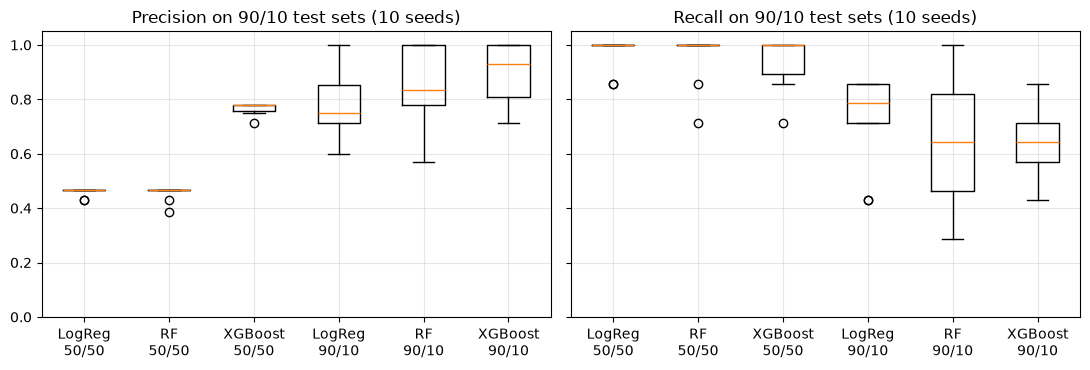

In [13]:
# Precision on the 90/10 test sets, per model and training setup (tuned thresholds).
t = long[(long.test_set == "imbalanced_test") & (long.threshold_type == "tuned")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ["precision", "recall"]):
    data = [t[(t.model == m) & (t.trained_on == c)][metric] for c in ["balanced", "imbalanced"] for m in MODEL_NAMES]
    ax.boxplot(data, tick_labels=[f"{NAMES[m]}\n{CFG[c]}" for c in ["balanced", "imbalanced"] for m in MODEL_NAMES])
    ax.set(title=f"{metric.capitalize()} on 90/10 test sets (10 seeds)", ylim=(0, 1.05))
    ax.grid(alpha=0.3)
fig.tight_layout()

## 6. Discussion
- **Models trained on 50/50 data over-flag at realistic ratios.** On a 90/10 test set, about half of LogReg's and RF's fake flags are genuine accounts (precision ≈ 0.46 at the tuned threshold). Recall stays high.
- **Models trained on 90/10 data have the opposite problem.** Precision is higher, but they miss about a third of the fakes. They had only 32 fake training examples, and their results vary a lot from seed to seed.
- **XGBoost trained on 50/50 data is the best overall,** with F1 ≈ 0.84 on 90/10 test data and the highest PR-AUC. Its tuned threshold (0.62) is stricter than 0.5, which offsets the over-flagging.
- **The class ratio mostly shifts where the threshold should sit,** not how well the models rank accounts: PR-AUC stays high for every model. Notebook 03 tests whether this holds on live Instagram data.

*Note:* each 90/10 test set has only 60 genuine and 7 fake accounts, so the std is large.